# ส่งทีมไหนดี? ทำนายอุบัติเหตุที่มีผู้เสียชีวิตตั้งแต่ตอนรับแจ้งทำนายว่าอุบัติเหตุทางถนนที่เพิ่งได้รับแจ้งจะมีผู้เสียชีวิตหรือไม่ โดยใช้เฉพาะข้อมูลที่รู้ ณ เวลารับแจ้ง  เพื่อช่วยศูนย์สั่งการ 1669 ตัดสินใจว่าจะส่งทีมกู้ชีพขั้นสูง  หรือทีมพื้นฐาน
**SDG 11 เมืองและชุมชนที่ยั่งยืน · CPE312 DS Capstone 2569**

**กลุ่ม:** HDB

| สมาชิก | บทบาท |
|---|---|
| ภูวกร จิรอานันท์ | ผู้ดูแลข้อมูล |
| ภูวกร จิรอานันท์ | ผู้สร้างโมเดล |
|ศิกวัส รัตน์วัฒนชัยกุล| ผู้เล่าเรื่อง |
ชวัลลักษณฺ์ แผนสท้าน| ผู้เล่าเรื่อง |
| ภูวกร จิรอานันท์ | ผู้ตรวจคุณภาพ |

**แหล่งข้อมูล:** [Thailand Road Accident 2019–2022 (Kaggle)](https://www.kaggle.com/datasets/thaweewatboy/thailand-road-accident-2019-2022) · license: https://creativecommons.org/publicdomain/zero/1.0/(CC0 1.0)

| ส่วนใน notebook | ข้อกำหนด |
|---|---|
| R1 การตั้งโจทย์ | R1 |
| Part 1 โหลดข้อมูล | ลงทะเบียน |
| Part 2 เตรียมข้อมูล + แบ่ง train/test | R2 |
| Part 3 EDA | R3 |
| Part 4 baseline เทียบโมเดล | R4 |
| Part 5 โมเดลพลาดตรงไหน | R5 |
| Part 6 ข้อเสนอแนะ + ต้นทุน + ข้อจำกัด | R6 |
| Part 7 บันทึกการใช้ AI | R7 |
| สรุปตัวเลขสำหรับโปสเตอร์ | ใช้เช็กว่าตัวเลขบนโปสเตอร์ตรงกับ notebook |



# R1 · การตั้งโจทย์ (Business Understanding)

**โจทย์:** ทำนายว่าอุบัติเหตุทางถนนที่เพิ่งได้รับแจ้งจะมีผู้เสียชีวิตหรือไม่ โดยใช้เฉพาะข้อมูลที่รู้ ณ เวลารับแจ้ง เพื่อช่วยศูนย์สั่งการ 1669 ตัดสินใจว่าจะส่งทีมกู้ชีพขั้นสูง (ALS) หรือทีมพื้นฐาน

| เกณฑ์ | คำตอบ |
|---|---|
| 1. ใครใช้ / ตัดสินใจอะไร | เจ้าหน้าที่ศูนย์สั่งการ 1669 ตัดสินใจว่าจะส่งทีม ALS หรือทีมพื้นฐาน |
| 2. ทำนายเมื่อไร / ข้อมูลมีจริงไหม | ทันทีที่รับแจ้ง ใช้เฉพาะ: ประเภทรถ จำนวนรถ ลักษณะถนน ความลาดชัน สภาพอากาศ วัน-เวลา จังหวัด หน่วยงานเจ้าของถนน · **ไม่ใช้** จำนวนผู้บาดเจ็บ สาเหตุที่สันนิษฐาน ลักษณะการชน เวลาบันทึกเข้าระบบ (รู้ทีหลัง) |
| 3. 1 แถว = | อุบัติเหตุ 1 ครั้ง |
| 4. เป้าหมาย | `fatal` = 1 ถ้ามีผู้เสียชีวิตอย่างน้อย 1 คน, 0 ถ้าไม่มี |
| 5. ความผิดพลาดที่แพงกว่า | ทายว่าไม่รุนแรงแต่มีคนเสียชีวิตจริง (False Negative) แพงกว่าส่ง ALS เกินจำเป็น → ตัววัดหลัก = **Recall ของคลาสเสียชีวิต** และดู **สัดส่วนเคสที่ต้องส่ง ALS** ประกอบ เพื่อไม่ให้ส่งพร่ำเพรื่อจนทีมไม่พอ |

**ทำไมสำคัญ (SDG 11):** ประเทศไทยมีผู้เสียชีวิตจากอุบัติเหตุทางถนนสูงมาก ทีม ALS มีจำกัด ถ้าส่งทีมที่เหมาะกับความรุนแรงได้ตั้งแต่แรก ผู้บาดเจ็บสาหัสจะได้รับการดูแลขั้นสูงเร็วขึ้น

> โมเดลเป็น **ตัวช่วยเสริม** เกณฑ์คัดแยกที่ 1669 ใช้อยู่ ไม่ได้มาแทนเจ้าหน้าที่

In [ ]:
!pip install -q kagglehub

import glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

pd.set_option("display.max_columns", 50)

# สไตล์กราฟ: เส้นกริดจาง สีเดียว อ่านง่ายบนโปสเตอร์
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e5e5e5",
    "axes.axisbelow": True,
})
ACCENT = "#c0392b"   # สีหลักของกราฟ
MUTED = "#9a9a9a"    # สีเส้นอ้างอิง

# Part 1 · โหลดข้อมูล

In [ ]:
path = kagglehub.dataset_download("thaweewatboy/thailand-road-accident-2019-2022")
csv_files = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)
print("ไฟล์ที่พบ:", csv_files)

df = pd.read_csv(csv_files[0])

100%|██████████| 7.37M/7.37M [00:00<00:00, 58.7MB/s]

Extracting files...


ไฟล์ที่พบ: ['/root/.cache/kagglehub/datasets/thaweewatboy/thailand-road-accident-2019-2022/versions/1/thai_road_accident_2019_2022.csv']


In [ ]:
# ทางเลือกสำรอง: ถ้าเซลล์ข้างบนดาวน์โหลดไม่ได้
# ให้กด Download บนหน้า Kaggle แล้วเอาเครื่องหมาย # ออกจาก 3 บรรทัดล่างนี้ จากนั้นรันเพื่ออัปโหลด CSV เอง
# from google.colab import files
# uploaded = files.upload()
# df = pd.read_csv(list(uploaded.keys())[0])

In [ ]:
print(f"จำนวนแถว:    {len(df):,}")
print(f"จำนวนคอลัมน์: {df.shape[1]}")
df.head()

จำนวนแถว:    81,735
จำนวนคอลัมน์: 18


,acc_code,incident_datetime,report_datetime,province_th,province_en,agency,route,vehicle_type,presumed_cause,accident_type,number_of_vehicles_involved,number_of_fatalities,number_of_injuries,weather_condition,latitude,longitude,road_description,slope_description
0,571905,2019-01-01 00:00:00,2019-01-02 06:11:00,ลพบุรี,Loburi,department of rural roads,แยกทางหลวงหมายเลข 21 (กม.ที่ 31+000) - บ้านวัง...,motorcycle,driving under the influence of alcohol,other,1,0,2,clear,14.959105,100.873463,straight road,no slope
1,3790870,2019-01-01 00:03:00,2020-02-20 13:48:00,อุบลราชธานี,Ubon Ratchathani,department of highways,เดชอุดม - อุบลราชธานี,private/passenger car,speeding,rollover/fallen on straight road,1,0,2,clear,15.210738,104.862689,straight road,no slope
2,599075,2019-01-01 00:05:00,2019-01-01 10:35:00,ประจวบคีรีขันธ์,Prachuap Khiri Khan,department of highways,ปราณบุรี - ปากน้ำปราณ,motorcycle,speeding,head-on collision (not overtaking),2,1,0,clear,12.374259,99.907949,wide curve,slope area
3,571924,2019-01-01 00:20:00,2019-01-02 05:12:00,เชียงใหม่,Chiang Mai,department of rural roads,เชื่อมทางหลวงหมายเลข 1013 (กม.ที่ 8+200) - บ้า...,motorcycle,driving under the influence of alcohol,other,1,0,1,clear,18.601721,98.804204,straight road,no slope
4,599523,2019-01-01 00:25:00,2019-01-04 09:42:00,นครสวรรค์,Nakhon Sawan,department of highways,เกยไชย - ศรีมงคล,private/passenger car,cutting in closely by people/vehicles/animals,rollover/fallen on straight road,1,0,0,clear,15.866389,100.590010,straight road,no slope


In [ ]:
# ชนิดข้อมูล ค่าที่หาย และจำนวนค่าไม่ซ้ำของแต่ละคอลัมน์ (ใช้เขียน R2)
pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique": df.nunique(),
})

,dtype,missing,unique
acc_code,int64,0,81735
incident_datetime,object,0,67917
report_datetime,object,0,66234
province_th,object,0,78
province_en,object,0,78
agency,object,0,3
route,object,0,3882
vehicle_type,object,0,15
presumed_cause,object,0,54
accident_type,object,0,11


In [ ]:
df["incident_datetime"] = pd.to_datetime(df["incident_datetime"], errors="coerce")
df["report_datetime"] = pd.to_datetime(df["report_datetime"], errors="coerce")
df["year"] = df["incident_datetime"].dt.year

# เป้าหมาย: 1 = มีผู้เสียชีวิตอย่างน้อย 1 คน
df["fatal"] = (df["number_of_fatalities"] > 0).astype(int)

n0, n1 = (df["fatal"] == 0).sum(), (df["fatal"] == 1).sum()
print(f"ไม่มีผู้เสียชีวิต (0): {n0:,} ({n0/len(df):.1%})")
print(f"มีผู้เสียชีวิต   (1): {n1:,} ({n1/len(df):.1%})")
print(f"\nถ้าทายว่า 'ไม่มีผู้เสียชีวิต' ทุกเคส → accuracy = {n0/len(df):.1%} แต่ recall = 0")

ไม่มีผู้เสียชีวิต (0): 71,600 (87.6%)
มีผู้เสียชีวิต   (1): 10,135 (12.4%)

ถ้าทายว่า 'ไม่มีผู้เสียชีวิต' ทุกเคส → accuracy = 87.6% แต่ recall = 0


# Part 2 · เตรียมข้อมูล (R2)

ลำดับ:
1. ตรวจปัญหาข้อมูล
2. ตัดคอลัมน์ที่เป็น **data leakage** (ไม่รู้ ณ เวลารับแจ้ง)
3. สร้าง feature จากเวลาเกิดเหตุ
4. แบ่ง train / test **ตามเวลา**
5. รวมหมวดที่มีน้อยเป็น `other` (คำนวณจาก train เท่านั้น)

## 2.1 ตรวจปัญหาข้อมูล

In [ ]:
issues = {}

issues["incident_datetime แปลงไม่ได้"] = df["incident_datetime"].isna().sum()
issues["ไม่มีพิกัด (lat/lon)"] = df["latitude"].isna().sum()
issues["จังหวัด = unknown"] = (df["province_en"].str.lower() == "unknown").sum()
issues["แถวซ้ำทั้งแถว"] = df.duplicated().sum()

delay_days = (df["report_datetime"] - df["incident_datetime"]).dt.total_seconds() / 86400
issues["บันทึกเข้าระบบช้ากว่า 1 วัน"] = (delay_days > 1).sum()
issues["บันทึกเข้าระบบช้ากว่า 30 วัน"] = (delay_days > 30).sum()
issues["เวลาบันทึกก่อนเวลาเกิดเหตุ"] = (delay_days < 0).sum()

pd.Series(issues, name="จำนวนแถว").to_frame()

,จำนวนแถว
incident_datetime แปลงไม่ได้,0
ไม่มีพิกัด (lat/lon),359
จังหวัด = unknown,34
แถวซ้ำทั้งแถว,0
บันทึกเข้าระบบช้ากว่า 1 วัน,73039
บันทึกเข้าระบบช้ากว่า 30 วัน,48874
เวลาบันทึกก่อนเวลาเกิดเหตุ,1


In [ ]:
# สรุปค่าในคอลัมน์หมวดหมู่หลัก (ดูว่ามี 'other' หรือหมวดเล็ก ๆ เยอะไหม)
for col in ["vehicle_type", "weather_condition", "road_description", "slope_description", "agency"]:
    vc = df[col].value_counts()
    print(f"\n=== {col}: {len(vc)} หมวด ===")
    print(vc.head(8).to_string())


=== vehicle_type: 15 หมวด ===
vehicle_type
4-wheel pickup truck        28445
private/passenger car       20814
motorcycle                  14874
large truck with trailer     6257
other                        3513
6-wheel truck                3019
7-10-wheel truck             2364
van                           842

=== weather_condition: 7 หมวด ===
weather_condition
clear               69943
rainy               10670
foggy                 544
dark                  368
other                 162
natural disaster       47
land slide              1

=== road_description: 19 หมวด ===
road_description
straight road                           58183
wide curve                              12552
other                                    7614
connecting to public/commercial area     1001
sharp curve                               616
connecting to private area                463
t-intersection                            414
four-way intersection                     348

=== slope_description: 3 หมว

## 2.2 ตัดคอลัมน์ที่เป็น data leakage

ศูนย์ 1669 ทำนายตอน **รับแจ้ง** จึงใช้ได้เฉพาะข้อมูลที่ผู้แจ้งบอกได้ ณ เวลานั้น

> **การตัดสินใจเรื่อง `accident_type`:** **ไม่ใช้** เพราะค่าในข้อมูลเป็นลักษณะการชนที่เจ้าหน้าที่บันทึกหลังตรวจที่เกิดเหตุ
> (เช่น "rollover on curved road", "collision at intersection corner") ละเอียดกว่าที่คนโทรแจ้งบอกได้ ถ้าใช้จะขัดกับ R1 ข้อ 2

In [ ]:
USE_ACCIDENT_TYPE = False

LEAKAGE = {
    "number_of_fatalities": "คือคำตอบ (target) โดยตรง",
    "number_of_injuries":   "รู้หลังทีมไปถึงที่เกิดเหตุ",
    "presumed_cause":       "สาเหตุที่สรุปภายหลังจากการสอบสวน",
    "report_datetime":      "เวลาบันทึกเข้าระบบ ไม่ใช่เวลาโทรแจ้ง (บางแถวช้าเป็นปี)",
}
NOT_USEFUL = {
    "acc_code":    "เป็นรหัสอ้างอิง ไม่มีความหมาย",
    "province_th": "ซ้ำกับ province_en",
    "route":       "มีค่าไม่ซ้ำหลายพันค่า ใช้ตรง ๆ ไม่ได้",
    "latitude":    "ใช้จังหวัดแทนในรอบแรก",
    "longitude":   "ใช้จังหวัดแทนในรอบแรก",
}
if not USE_ACCIDENT_TYPE:
    LEAKAGE["accident_type"] = "ลักษณะการชนที่เจ้าหน้าที่บันทึกหลังตรวจที่เกิดเหตุ"

pd.DataFrame(
    [(c, "leakage", r) for c, r in LEAKAGE.items()] +
    [(c, "ไม่ใช้", r) for c, r in NOT_USEFUL.items()],
    columns=["column", "เหตุผลที่ตัด", "คำอธิบาย"],
)

,column,เหตุผลที่ตัด,คำอธิบาย
0,number_of_fatalities,leakage,คือคำตอบ (target) โดยตรง
1,number_of_injuries,leakage,รู้หลังทีมไปถึงที่เกิดเหตุ
2,presumed_cause,leakage,สาเหตุที่สรุปภายหลังจากการสอบสวน
3,report_datetime,leakage,เวลาบันทึกเข้าระบบ ไม่ใช่เวลาโทรแจ้ง (บางแถวช้...
4,accident_type,leakage,ลักษณะการชนที่เจ้าหน้าที่บันทึกหลังตรวจที่เกิด...
5,acc_code,ไม่ใช้,เป็นรหัสอ้างอิง ไม่มีความหมาย
6,province_th,ไม่ใช้,ซ้ำกับ province_en
7,route,ไม่ใช้,มีค่าไม่ซ้ำหลายพันค่า ใช้ตรง ๆ ไม่ได้
8,latitude,ไม่ใช้,ใช้จังหวัดแทนในรอบแรก
9,longitude,ไม่ใช้,ใช้จังหวัดแทนในรอบแรก


## 2.3 สร้าง feature จากเวลาเกิดเหตุ

In [ ]:
data = df.dropna(subset=["incident_datetime"]).copy()
t = data["incident_datetime"]

data["hour"] = t.dt.hour
data["dayofweek"] = t.dt.dayofweek          # 0 = จันทร์ ... 6 = อาทิตย์
data["month"] = t.dt.month
data["is_weekend"] = (data["dayofweek"] >= 5).astype(int)
data["is_night"] = ((data["hour"] >= 18) | (data["hour"] < 6)).astype(int)

mmdd = t.dt.strftime("%m-%d")
data["is_songkran"] = mmdd.between("04-11", "04-17").astype(int)               # 7 วันอันตรายสงกรานต์
data["is_newyear"] = ((mmdd >= "12-29") | (mmdd <= "01-04")).astype(int)    # 7 วันอันตรายปีใหม่

CAT_FEATURES = ["agency", "province_en", "vehicle_type", "weather_condition",
                "road_description", "slope_description"]
if USE_ACCIDENT_TYPE:
    CAT_FEATURES.append("accident_type")
NUM_FEATURES = ["number_of_vehicles_involved", "hour", "dayofweek", "month",
                "is_weekend", "is_night", "is_songkran", "is_newyear"]
FEATURES = CAT_FEATURES + NUM_FEATURES
TARGET = "fatal"

print("feature ที่ใช้:", len(FEATURES))
print("  หมวดหมู่:", CAT_FEATURES)
print("  ตัวเลข:  ", NUM_FEATURES)

feature ที่ใช้: 14
  หมวดหมู่: ['agency', 'province_en', 'vehicle_type', 'weather_condition', 'road_description', 'slope_description']
  ตัวเลข:   ['number_of_vehicles_involved', 'hour', 'dayofweek', 'month', 'is_weekend', 'is_night', 'is_songkran', 'is_newyear']


## 2.4 แบ่ง train / test ตามเวลา

ข้อมูลมีลำดับเวลา จึง **ห้ามสุ่มแบ่ง** เพราะจะทำให้โมเดลได้เห็นข้อมูลอนาคตตอนเรียนรู้
- **train:** 2019–2021
- **test:** 2022 (จำลองว่าใช้โมเดลกับปีที่ยังไม่เคยเห็น)

In [ ]:
train = data[data["year"] <= 2021].copy()
test = data[data["year"] == 2022].copy()

split_summary = pd.DataFrame({
    "ช่วงปี": [f"{int(train['year'].min())}–{int(train['year'].max())}", "2022"],
    "จำนวนแถว": [len(train), len(test)],
    "เคสเสียชีวิต": [train[TARGET].sum(), test[TARGET].sum()],
    "สัดส่วนเสียชีวิต (%)": [round(train[TARGET].mean() * 100, 2), round(test[TARGET].mean() * 100, 2)],
}, index=["train", "test"])
split_summary

,ช่วงปี,จำนวนแถว,เคสเสียชีวิต,สัดส่วนเสียชีวิต (%)
train,2019–2021,60703,7860,12.95
test,2022,21032,2275,10.82


## 2.5 รวมหมวดที่มีน้อยเป็น `other`

นับความถี่จาก **train เท่านั้น** แล้วนำกฎเดียวกันไปใช้กับ test (ถ้าใช้ข้อมูล test มาตัดสินจะเป็น leakage แบบหนึ่ง)

In [ ]:
MIN_COUNT = 100   # หมวดที่มีใน train น้อยกว่านี้ → other

keep_levels = {}
for col in CAT_FEATURES:
    vc = train[col].fillna("unknown").value_counts()
    keep_levels[col] = set(vc[vc >= MIN_COUNT].index)

def group_rare(frame):
    out = frame.copy()
    for col in CAT_FEATURES:
        s = out[col].fillna("unknown")
        out[col] = s.where(s.isin(keep_levels[col]), "other")
    return out

train = group_rare(train)
test = group_rare(test)

pd.DataFrame({
    "หมวดที่เก็บไว้": {c: len(keep_levels[c]) for c in CAT_FEATURES},
    "แถวใน test ที่กลายเป็น other": {c: (test[c] == "other").sum() for c in CAT_FEATURES},
})

,หมวดที่เก็บไว้,แถวใน test ที่กลายเป็น other
agency,3,0
province_en,77,6
vehicle_type,13,1126
weather_condition,4,85
road_description,9,2485
slope_description,3,3574


# Part 3 · EDA: ข้อมูลบอกอะไร (R3)

ดูจาก **train เท่านั้น** เพื่อไม่ให้สิ่งที่เห็นใน test มาชี้นำการออกแบบโมเดล

คำถามหลัก: **อุบัติเหตุแบบไหนมีโอกาสมีผู้เสียชีวิตสูงกว่าค่าเฉลี่ย?**

In [ ]:
BASE_RATE = train[TARGET].mean() * 100

def fatal_rate(frame, col, min_n=200):
    g = frame.groupby(col)[TARGET].agg(n="size", fatal="sum", rate="mean")
    g["rate_%"] = (g.pop("rate") * 100).round(2)
    return g[g["n"] >= min_n].sort_values("rate_%", ascending=False)

def bar_rate(table, title, xlabel=None):
    xlabel = xlabel or f"Fatal accidents (%)   ·   dashed line = average {BASE_RATE:.1f}%"
    tbl = table.sort_values("rate_%")
    fig, ax = plt.subplots(figsize=(7, 0.38 * len(tbl) + 1.2))
    ax.barh(tbl.index.astype(str), tbl["rate_%"], color=ACCENT, height=0.6)
    ax.axvline(BASE_RATE, color=MUTED, ls="--", lw=1.5)
    for i, (rate, n) in enumerate(zip(tbl["rate_%"], tbl["n"])):
        ax.text(rate, i, f" {rate:.1f}%  (n={n:,})", va="center", fontsize=8.5, color="#333")
    ax.set_title(title, loc="left", fontsize=12)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, tbl["rate_%"].max() * 1.35)
    plt.tight_layout()
    plt.show()

print(f"อัตราเสียชีวิตเฉลี่ยใน train: {BASE_RATE:.2f}%")

อัตราเสียชีวิตเฉลี่ยใน train: 12.95%


## 3.1 ประเภทรถ

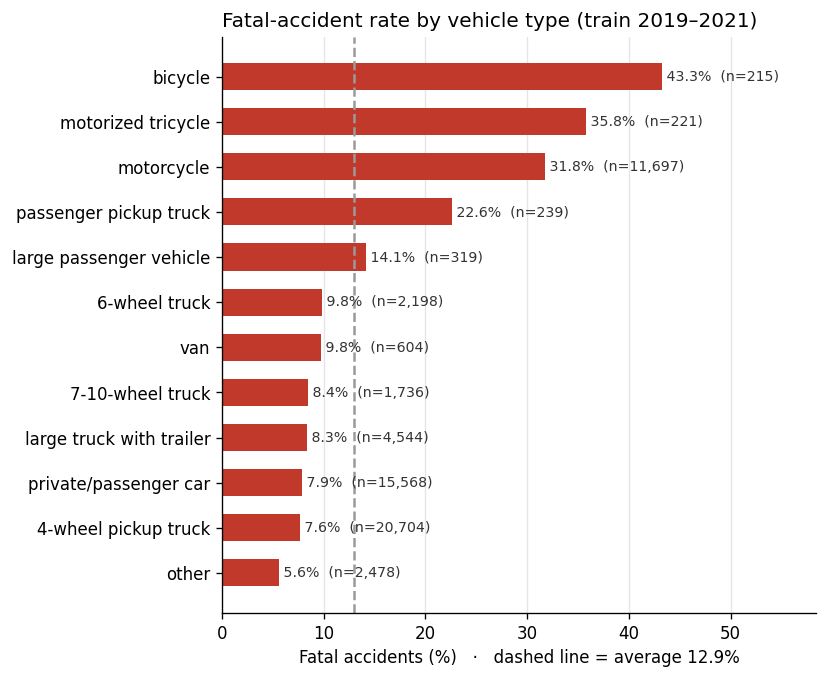

รถจักรยานยนต์ = 19% ของอุบัติเหตุ แต่ = 47% ของเคสเสียชีวิต


<Figure size 768x576 with 0 Axes>

In [ ]:
vt = fatal_rate(train, "vehicle_type")
bar_rate(vt, "Fatal-accident rate by vehicle type (train 2019–2021)")
vt

moto = train[train["vehicle_type"] == "motorcycle"]
print(f"รถจักรยานยนต์ = {len(moto)/len(train):.0%} ของอุบัติเหตุ แต่ = {moto[TARGET].sum()/train[TARGET].sum():.0%} ของเคสเสียชีวิต")

plt.savefig("R3_vehicle.png", dpi=300, bbox_inches="tight")

## 3.2 ช่วงเวลาของวัน

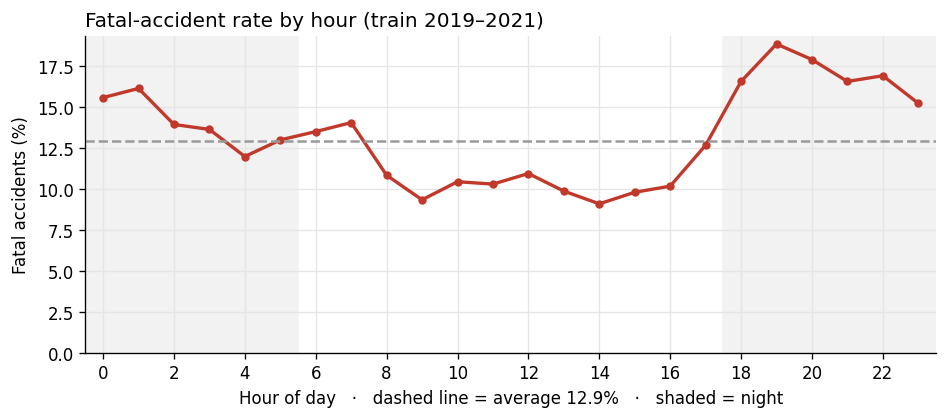

กลางวัน (06–18): 10.78%   กลางคืน (18–06): 15.93%


In [ ]:
hr = train.groupby("hour")[TARGET].agg(n="size", rate="mean")
hr["rate_%"] = hr["rate"] * 100

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.axvspan(-0.5, 5.5, color="#f2f2f2", zorder=0)
ax.axvspan(17.5, 23.5, color="#f2f2f2", zorder=0)
ax.plot(hr.index, hr["rate_%"], color=ACCENT, lw=2, marker="o", ms=4)
ax.axhline(BASE_RATE, color=MUTED, ls="--", lw=1.5)
ax.set_xticks(range(0, 24, 2))
ax.set_xlim(-0.5, 23.5)
ax.set_ylim(bottom=0)
ax.set_xlabel(f"Hour of day   ·   dashed line = average {BASE_RATE:.1f}%   ·   shaded = night")
ax.set_ylabel("Fatal accidents (%)")
ax.set_title("Fatal-accident rate by hour (train 2019–2021)", loc="left", fontsize=12)
plt.tight_layout()
plt.show()

night = train.groupby("is_night")[TARGET].mean() * 100
print(f"กลางวัน (06–18): {night.get(0, np.nan):.2f}%   กลางคืน (18–06): {night.get(1, np.nan):.2f}%")

## 3.3 ลักษณะถนนและสภาพอากาศ

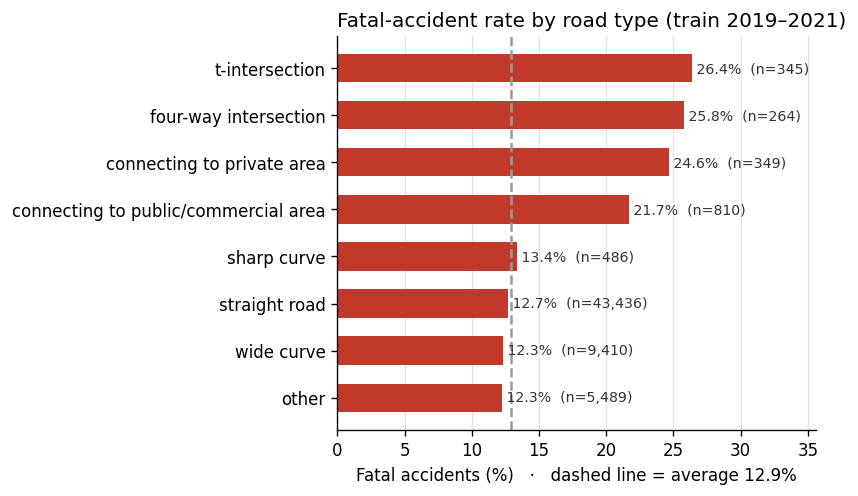

,n,fatal,rate_%
road_description,,,
t-intersection,345,91,26.38
four-way intersection,264,68,25.76
connecting to private area,349,86,24.64
connecting to public/commercial area,810,176,21.73
sharp curve,486,65,13.37
straight road,43436,5518,12.70
wide curve,9410,1157,12.30
other,5489,674,12.28


In [ ]:
rd = fatal_rate(train, "road_description")
bar_rate(rd, "Fatal-accident rate by road type (train 2019–2021)")
rd

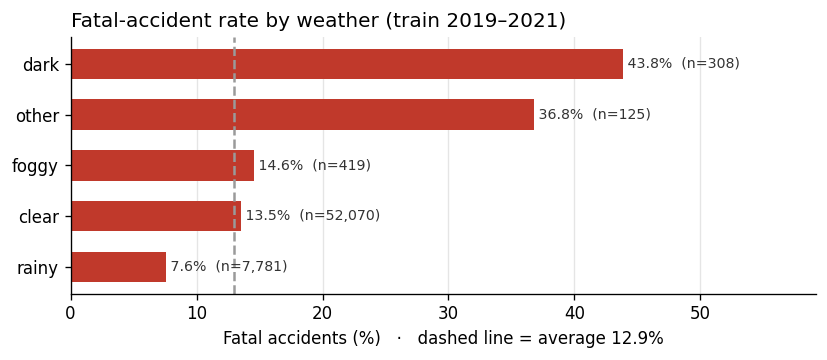

,n,fatal,rate_%
weather_condition,,,
dark,308,135,43.83
other,125,46,36.80
foggy,419,61,14.56
clear,52070,7027,13.50
rainy,7781,591,7.60


In [ ]:
wc = fatal_rate(train, "weather_condition", min_n=100)
bar_rate(wc, "Fatal-accident rate by weather (train 2019–2021)")
wc

## 3.4 ช่วงเทศกาล

In [ ]:
fest = pd.DataFrame({
    "n": [len(train[train.is_songkran == 1]), len(train[train.is_newyear == 1]),
          len(train[(train.is_songkran == 0) & (train.is_newyear == 0)])],
    "rate_%": [train.loc[train.is_songkran == 1, TARGET].mean() * 100,
               train.loc[train.is_newyear == 1, TARGET].mean() * 100,
               train.loc[(train.is_songkran == 0) & (train.is_newyear == 0), TARGET].mean() * 100],
}, index=["Songkran 7 days", "New Year 7 days", "Other days"]).round(2)
fest

,n,rate_%
Songkran 7 days,3319,13.26
New Year 7 days,4611,12.77
Other days,52773,12.94


## 3.5 สรุปข้อค้นพบ (กลุ่มเขียนเองจากตัวเลขจริงด้านบน)

ใช้เป็นข้อความใต้กราฟ R3 บนโปสเตอร์ เลือกกราฟที่ต่างจากค่าเฉลี่ยชัดที่สุด 1 รูป

- **ข้อค้นพบหลัก:** อุบัติเหตุรถจักรยานยนต์มีผู้เสียชีวิต 31.8% สูงกว่าค่าเฉลี่ย 12.9% ราว 2.5 เท่า และสูงกว่ารถเก๋ง (7.9%) ราว 4 เท่า

- **ข้อค้นพบรอง:** อุบัติเหตุกลางคืน (18:00–06:00) มีอัตราเสียชีวิต 15.9% เทียบกับกลางวัน 10.8% สูงสุดช่วงราว 19:00 น.
- **ความหมายต่อโจทย์:** ประเภทรถและเวลาเป็นข้อมูลที่ผู้แจ้งบอกได้ทันที และแยกเคสเสี่ยงสูงได้ชัด จึงมีเหตุผลที่จะใช้สร้างโมเดลช่วย 1669
- **ข้อควรระวัง:** เคสเสียชีวิตมีเพียง 12.9% ข้อมูลไม่สมดุล จึงวัดด้วย recall ไม่ใช่ accuracy · จักรยานและสามล้อเครื่องมีอัตราสูงแต่มีเคสน้อย (~200) จึงไม่ได้ใช้เป็นข้อสรุปหลัก

# Part 4 · Baseline เทียบโมเดล (R4)

**วิธีเลือกอย่างยุติธรรม (ไม่แตะ test จนถึงขั้นสุดท้าย):**
1. แบ่ง train ย่อยเป็น **fit = 2019–2020** และ **validation = 2021**
2. เลือกโมเดลและ threshold บน validation
3. เทรนใหม่ด้วย train ทั้งหมด (2019–2021) แล้วประเมินบน **test 2022** ครั้งเดียว

**ทำไมต้องเลือก threshold:** โมเดลให้ "ความน่าจะเป็นที่จะมีผู้เสียชีวิต" ศูนย์ 1669 ต้องกำหนดเส้นว่าเกินเท่าไรถึงส่ง ALS
เราเลือกเส้นที่ **ส่ง ALS น้อยที่สุด แต่ยังจับเคสเสียชีวิตได้อย่างน้อย `TARGET_RECALL`** (ตาม R1 ข้อ 5)

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, precision_recall_curve, confusion_matrix
from sklearn.inspection import permutation_importance

SEED = 42
TARGET_RECALL = 0.85

def make_preprocess():
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_FEATURES),
        ("num", StandardScaler(), NUM_FEATURES),
    ])

MODELS = {
    "Logistic Regression": lambda: Pipeline([
        ("prep", make_preprocess()),
        ("clf", LogisticRegression(class_weight="balanced", max_iter=2000)),
    ]),
    "Random Forest": lambda: Pipeline([
        ("prep", make_preprocess()),
        ("clf", RandomForestClassifier(n_estimators=200, min_samples_leaf=20,
                                       class_weight="balanced_subsample",
                                       n_jobs=-1, random_state=SEED)),
    ]),
}

def threshold_for_recall(y_true, proba, target):
    """threshold สูงสุด (= ส่ง ALS น้อยที่สุด) ที่ยังได้ recall >= target"""
    _, rec, thr = precision_recall_curve(y_true, proba)
    ok = np.where(rec[:-1] >= target)[0]
    return float(thr[ok[-1]]) if len(ok) else float(thr[0])

def evaluate(name, y_true, pred, proba=None):
    y_true = np.asarray(y_true)
    pred = np.asarray(pred)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "model": name,
        "recall": tp / (tp + fn) if tp + fn else 0.0,
        "precision": tp / (tp + fp) if tp + fp else 0.0,
        "accuracy": (tp + tn) / len(y_true),
        "ส่ง ALS (% ของเคส)": pred.mean() * 100,
        "จับได้ (TP)": tp,
        "พลาด (FN)": fn,
        "ส่งเกิน (FP)": fp,
        "PR-AUC": average_precision_score(y_true, proba) if proba is not None else np.nan,
    }

## 4.1 Baseline อย่างง่าย 2 แบบ
- **Baseline 1 · ทายคลาสที่พบบ่อยที่สุด:** ทายว่า "ไม่มีผู้เสียชีวิต" ทุกเคส (= ส่งทีมพื้นฐานทุกครั้ง)
- **Baseline 2 · กฎง่าย ๆ จาก EDA:** ส่ง ALS ถ้า **ประเภทรถมีอัตราเสียชีวิตสูงกว่าค่าเฉลี่ยใน train** หรือ **เกิดกลางคืน (18:00–06:00)**

In [ ]:
rates_vt = train.groupby("vehicle_type")[TARGET].mean()
HIGH_RISK_VEHICLES = sorted(rates_vt[rates_vt > train[TARGET].mean()].index)
print("ประเภทรถที่กฎถือว่าเสี่ยงสูง:", HIGH_RISK_VEHICLES)

def rule_baseline(frame):
    return (frame["vehicle_type"].isin(HIGH_RISK_VEHICLES) | (frame["is_night"] == 1)).astype(int)

ประเภทรถที่กฎถือว่าเสี่ยงสูง: ['bicycle', 'large passenger vehicle', 'motorcycle', 'motorized tricycle', 'passenger pickup truck', 'pedestrian']


## 4.2 เลือกโมเดลและ threshold บน validation (2021)

In [ ]:
fit_part = train[train["year"] <= 2020]
val_part = train[train["year"] == 2021]
print(f"fit 2019–2020: {len(fit_part):,} แถว · validation 2021: {len(val_part):,} แถว")

val_rows, THRESHOLDS = [], {}
for name, make in MODELS.items():
    m = make().fit(fit_part[FEATURES], fit_part[TARGET])
    p = m.predict_proba(val_part[FEATURES])[:, 1]
    THRESHOLDS[name] = threshold_for_recall(val_part[TARGET], p, TARGET_RECALL)
    row = evaluate(name, val_part[TARGET], (p >= THRESHOLDS[name]).astype(int), p)
    row["threshold"] = THRESHOLDS[name]
    val_rows.append(row)

val_table = pd.DataFrame(val_rows).set_index("model")
BEST_MODEL = val_table["PR-AUC"].idxmax()
print(f"\nโมเดลที่เลือก (PR-AUC บน validation สูงสุด): {BEST_MODEL}")
val_table[["PR-AUC", "threshold", "recall", "precision", "ส่ง ALS (% ของเคส)"]].round(3)

fit 2019–2020: 40,246 แถว · validation 2021: 20,457 แถว

โมเดลที่เลือก (PR-AUC บน validation สูงสุด): Random Forest


,PR-AUC,threshold,recall,precision,ส่ง ALS (% ของเคส)
model,,,,,
Logistic Regression,0.378,0.334,0.85,0.178,55.609
Random Forest,0.415,0.352,0.85,0.195,50.951


## 4.3 ผลบน test 2022 (ใช้ตัวเลขชุดนี้บนโปสเตอร์)
เทรนใหม่ด้วย train ทั้งหมด แล้วใช้ threshold ที่เลือกไว้จาก validation

In [ ]:
fitted, test_proba = {}, {}
for name, make in MODELS.items():
    fitted[name] = make().fit(train[FEATURES], train[TARGET])
    test_proba[name] = fitted[name].predict_proba(test[FEATURES])[:, 1]

y_test = test[TARGET].values
results = [
    evaluate("Baseline 1: ไม่เสียชีวิตทุกเคส", y_test, np.zeros(len(test), dtype=int)),
    evaluate("Baseline 2: กฎรถเสี่ยง/กลางคืน", y_test, rule_baseline(test).values),
]
for name in MODELS:
    results.append(evaluate(name, y_test, (test_proba[name] >= THRESHOLDS[name]).astype(int), test_proba[name]))

results_table = pd.DataFrame(results).set_index("model")
results_table.round(3)


,recall,precision,accuracy,ส่ง ALS (% ของเคส),จับได้ (TP),พลาด (FN),ส่งเกิน (FP),PR-AUC
model,,,,,,,,
Baseline 1: ไม่เสียชีวิตทุกเคส,0.000,0.000,0.892,0.000,0,2275,0,NaN
Baseline 2: กฎรถเสี่ยง/กลางคืน,0.733,0.149,0.520,53.048,1667,608,9490,NaN
Logistic Regression,0.840,0.168,0.534,54.003,1912,363,9446,0.344
Random Forest,0.829,0.201,0.624,44.675,1886,389,7510,0.400


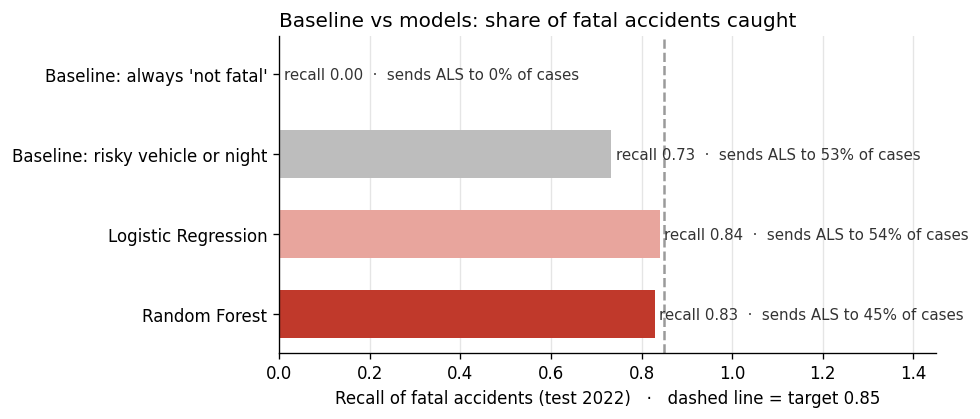

Baseline 1 ได้ accuracy 89.2% แต่ recall = 0 → accuracy ใช้วัดโจทย์นี้ไม่ได้


<Figure size 768x576 with 0 Axes>

In [ ]:
# กราฟ R4: recall บน test 2022 พร้อมต้นทุน (สัดส่วนเคสที่ต้องส่ง ALS)
tbl = results_table.iloc[::-1]
colors = [ACCENT if n == BEST_MODEL else ("#e8a59d" if n in MODELS else "#bdbdbd") for n in tbl.index]

# ชื่อบนกราฟเป็นภาษาอังกฤษ เพราะฟอนต์เริ่มต้นของ Colab ไม่มีตัวอักษรไทย
EN_LABELS = {"Baseline 1: ไม่เสียชีวิตทุกเคส": "Baseline: always 'not fatal'",
             "Baseline 2: กฎรถเสี่ยง/กลางคืน": "Baseline: risky vehicle or night"}
labels = [EN_LABELS.get(n, n) for n in tbl.index]

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(labels, tbl["recall"], color=colors, height=0.6)
for i, (r, a) in enumerate(zip(tbl["recall"], tbl["ส่ง ALS (% ของเคส)"])):
    ax.text(r + 0.01, i, f"recall {r:.2f}  ·  sends ALS to {a:.0f}% of cases", va="center", fontsize=9, color="#333")
ax.axvline(TARGET_RECALL, color=MUTED, ls="--", lw=1.5)
ax.set_xlim(0, 1.45)
ax.set_xlabel(f"Recall of fatal accidents (test 2022)   ·   dashed line = target {TARGET_RECALL:.2f}")
ax.set_title("Baseline vs models: share of fatal accidents caught", loc="left", fontsize=12)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

acc_b1 = results_table.iloc[0]["accuracy"]
print(f"Baseline 1 ได้ accuracy {acc_b1:.1%} แต่ recall = 0 → accuracy ใช้วัดโจทย์นี้ไม่ได้")

plt.savefig("R4_baseline.png", dpi=300, bbox_inches="tight")  # เซลล์ 4.3 (กราฟ)

# Part 5 · โมเดลพลาดตรงไหน (R5)

ดูเฉพาะโมเดลที่เลือก บน test 2022 · จุดพลาดที่แพงที่สุดคือ **False Negative** = มีผู้เสียชีวิตแต่โมเดลบอกให้ส่งทีมพื้นฐาน

In [ ]:
best_proba = test_proba[BEST_MODEL]
best_pred = (best_proba >= THRESHOLDS[BEST_MODEL]).astype(int)

ev = test.copy()
ev["proba"] = best_proba
ev["pred"] = best_pred
ev["outcome"] = np.select(
    [(ev[TARGET] == 1) & (ev["pred"] == 1), (ev[TARGET] == 1) & (ev["pred"] == 0),
     (ev[TARGET] == 0) & (ev["pred"] == 1)],
    ["TP จับได้", "FN พลาด", "FP ส่งเกิน"], default="TN ถูกต้อง")

cm = pd.crosstab(ev[TARGET].map({1: "จริง: มีผู้เสียชีวิต", 0: "จริง: ไม่มี"}),
                 ev["pred"].map({1: "โมเดล: ส่ง ALS", 0: "โมเดล: ทีมพื้นฐาน"}))
print(f"Confusion matrix · {BEST_MODEL} · test 2022")
cm

Confusion matrix · Random Forest · test 2022


pred,โมเดล: ทีมพื้นฐาน,โมเดล: ส่ง ALS
fatal,,
จริง: มีผู้เสียชีวิต,389,1886
จริง: ไม่มี,11247,7510


## 5.1 กลุ่มไหนที่โมเดลพลาดบ่อย
อัตราพลาด = ในเคสที่มีผู้เสียชีวิตจริงของกลุ่มนั้น โมเดลพลาดไปกี่ %

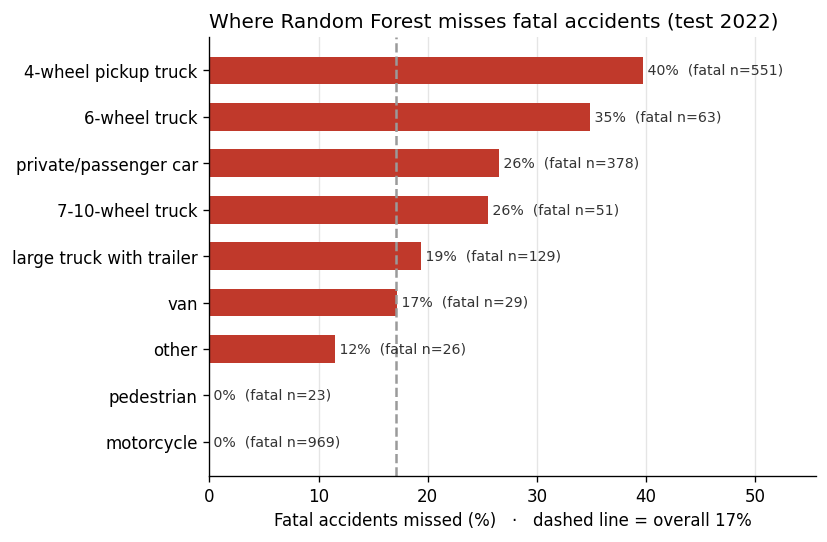

,n,caught,miss_%
vehicle_type,,,
4-wheel pickup truck,551,332,39.7
6-wheel truck,63,41,34.9
private/passenger car,378,278,26.5
7-10-wheel truck,51,38,25.5
large truck with trailer,129,104,19.4
van,29,24,17.2
other,26,23,11.5
motorcycle,969,969,0.0
pedestrian,23,23,0.0


In [ ]:
fatal_cases = ev[ev[TARGET] == 1]
OVERALL_MISS = (fatal_cases["pred"] == 0).mean() * 100

def miss_rate(col, min_n=20):
    g = fatal_cases.groupby(col)["pred"].agg(n="size", caught="sum")
    g["miss_%"] = ((1 - g["caught"] / g["n"]) * 100).round(1)
    return g[g["n"] >= min_n].sort_values("miss_%", ascending=False)

mr_vt = miss_rate("vehicle_type")
tbl = mr_vt.sort_values("miss_%")
fig, ax = plt.subplots(figsize=(7, 0.38 * len(tbl) + 1.2))
ax.barh(tbl.index.astype(str), tbl["miss_%"], color=ACCENT, height=0.6)
ax.axvline(OVERALL_MISS, color=MUTED, ls="--", lw=1.5)
for i, (m, n) in enumerate(zip(tbl["miss_%"], tbl["n"])):
    ax.text(m, i, f" {m:.0f}%  (fatal n={n})", va="center", fontsize=8.5, color="#333")
ax.set_xlim(0, max(tbl["miss_%"].max(), 1) * 1.4)
ax.set_xlabel(f"Fatal accidents missed (%)   ·   dashed line = overall {OVERALL_MISS:.0f}%")
ax.set_title(f"Where {BEST_MODEL} misses fatal accidents (test 2022)", loc="left", fontsize=12)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
mr_vt

In [ ]:
for col in ["is_night", "road_description", "weather_condition", "agency"]:
    print(f"\n=== อัตราพลาดตาม {col} ===")
    print(miss_rate(col).to_string())


=== อัตราพลาดตาม is_night ===
             n  caught  miss_%
is_night                      
0         1099     873    20.6
1         1176    1013    13.9

=== อัตราพลาดตาม road_description ===
                                         n  caught  miss_%
road_description                                          
wide curve                             303     238    21.5
straight road                         1561    1285    17.7
other                                  269     226    16.0
connecting to public/commercial area    38      36     5.3
connecting to private area              44      42     4.5
t-intersection                          25      25     0.0

=== อัตราพลาดตาม weather_condition ===
                      n  caught  miss_%
weather_condition                      
rainy               202     129    36.1
foggy                21      17    19.0
clear              2007    1697    15.4
dark                 27      27     0.0

=== อัตราพลาดตาม agency ===
                         

## 5.2 ตัวอย่างเคสที่พลาด
แสดงคอลัมน์ที่ **โมเดลไม่ได้ใช้** (`accident_type`, `presumed_cause`, `number_of_injuries`) ประกอบด้วย
เพื่อดูว่าเคสที่พลาดมีอะไรที่ข้อมูล ณ เวลารับแจ้งบอกไม่ได้

In [ ]:
fatal_cases.groupby("outcome")["number_of_vehicles_involved"].apply(lambda s: (s == 1).mean() * 100).round(1)

,number_of_vehicles_involved
outcome,
FN พลาด,88.7
TP จับได้,29.0


In [ ]:
show_cols = ["incident_datetime", "province_en", "vehicle_type", "road_description",
             "weather_condition", "number_of_vehicles_involved", "proba",
             "number_of_fatalities", "accident_type", "presumed_cause"]
fn_examples = ev[ev["outcome"] == "FN พลาด"].sort_values("proba")[show_cols].head(10)
fn_examples.round({"proba": 3})

,incident_datetime,province_en,vehicle_type,road_description,weather_condition,number_of_vehicles_involved,proba,number_of_fatalities,accident_type,presumed_cause
73674,2022-08-05 19:01:00,Bangkok,4-wheel pickup truck,straight road,clear,1,0.093,1,pedestrian collision,other
73635,2022-08-04 22:30:00,Bangkok,private/passenger car,straight road,clear,1,0.101,1,rollover/fallen on straight road,speeding
68780,2022-05-05 02:50:00,Bangkok,private/passenger car,straight road,clear,1,0.104,1,rollover/fallen on straight road,speeding
71213,2022-06-20 03:00:00,Bangkok,private/passenger car,straight road,clear,1,0.105,1,rollover/fallen on straight road,speeding
71206,2022-06-19 22:45:00,Bangkok,private/passenger car,straight road,clear,1,0.107,1,pedestrian collision,cutting in closely by people/vehicles/animals
69381,2022-05-14 23:00:00,Bangkok,private/passenger car,straight road,clear,1,0.116,1,pedestrian collision,speeding
75691,2022-09-14 13:00:00,Chon Buri,private/passenger car,straight road,clear,1,0.121,1,rollover/fallen on straight road,speeding
80403,2022-12-17 14:50:00,Chon Buri,private/passenger car,straight road,clear,4,0.125,1,rollover/fallen on straight road,speeding
72160,2022-07-09 16:20:00,Chumphon,4-wheel pickup truck,wide curve,rainy,1,0.151,1,rollover/fallen on curved road,speeding
73863,2022-08-09 07:47:00,Chon Buri,private/passenger car,straight road,clear,1,0.154,1,rollover/fallen on straight road,speeding


In [ ]:
# เคสที่พลาดกับเคสที่จับได้ ต่างกันตรงลักษณะการชนไหม (ข้อมูลที่รู้ทีหลัง)
compare = pd.crosstab(fatal_cases["accident_type"], fatal_cases["outcome"], normalize="columns") * 100
compare.round(1).sort_values(compare.columns[0], ascending=False).head(8)

outcome,FN พลาด,TP จับได้
accident_type,,
rollover/fallen on straight road,58.9,14.2
rollover/fallen on curved road,15.9,3.8
pedestrian collision,10.5,4.0
rear-end collision,8.0,39.4
collision with obstruction (on road surface),3.1,5.7
other,1.3,17.6
head-on collision (not overtaking),1.0,13.4
collision at intersection corner,0.8,1.6


## 5.3 โมเดลพึ่ง feature ไหนมากที่สุด
Permutation importance: สลับค่าของ feature ทีละตัวแล้วดูว่า PR-AUC ลดลงเท่าไร ยิ่งลดมาก ยิ่งสำคัญ

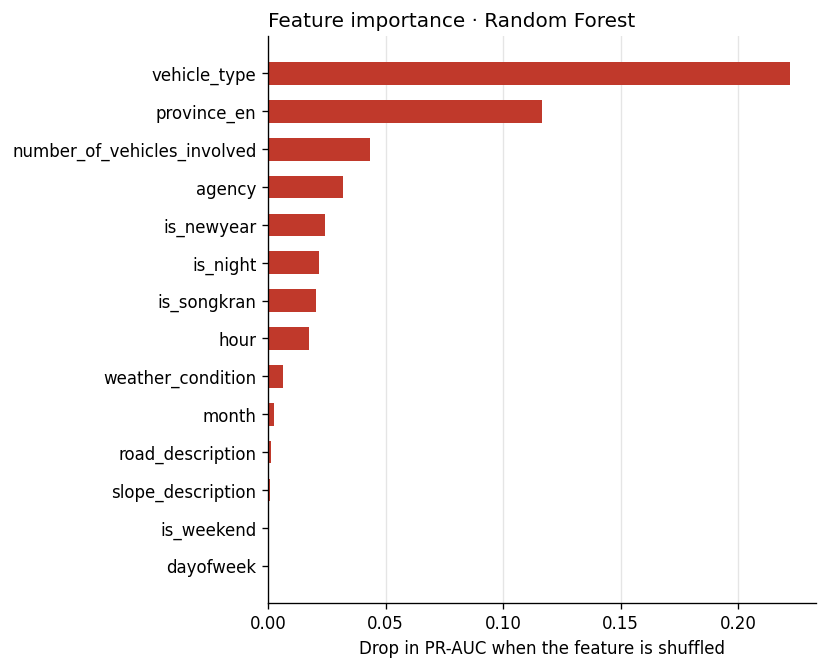

In [ ]:
sample = test.sample(n=min(8000, len(test)), random_state=SEED)
pi = permutation_importance(fitted[BEST_MODEL], sample[FEATURES], sample[TARGET],
                            scoring="average_precision", n_repeats=3, random_state=SEED, n_jobs=-1)
importance = pd.Series(pi.importances_mean, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(7, 0.32 * len(importance) + 1.2))
ax.barh(importance.index, importance.values, color=ACCENT, height=0.6)
ax.set_xlabel("Drop in PR-AUC when the feature is shuffled")
ax.set_title(f"Feature importance · {BEST_MODEL}", loc="left", fontsize=12)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 5.4 สรุปจุดพลาด

- **พลาดแบบไหน:** เคสเสียชีวิตที่โมเดลพลาด 82% เป็นรถกระบะ 4 ล้อและรถเก๋ง (กระบะพลาด 40%, รถเก๋งพลาด 26% เทียบกับภาพรวม 17%) · 89% ของเคสที่พลาดเป็นรถคันเดียว (เทียบกับ 29% ในเคสที่จับได้) · 75% เป็นรถพลิกคว่ำหรือตกถนน (เทียบกับ 18% ในเคสที่จับได้)
- **ทำไมพลาด:** ณ เวลารับแจ้ง เคสเหล่านี้ดูเสี่ยงต่ำ (รถเก๋งหรือกระบะ ทางตรง อากาศแจ่มใส) แต่ความรุนแรงจริงมาจากความเร็วและการพลิกคว่ำ ซึ่งไม่อยู่ในข้อมูลที่โมเดลใช้ · เคสชนคนเดินเท้าก็พลาดบ่อย เพราะข้อมูลบอกประเภทรถ ไม่ได้บอกว่าผู้เสียชีวิตเป็นคนเดินเท้า
- **หลักฐาน:** กราฟ 5.1, ตัวอย่างเคสที่พลาด (5.2), ตารางเทียบลักษณะการชน

# Part 6 · ข้อเสนอแนะ ต้นทุน และข้อจำกัด (R6)

## 6.1 ต้นทุนของการเลือก threshold
ถ้าส่ง ALS ให้เคสมากขึ้น จะจับเคสเสียชีวิตได้มากขึ้น แต่ใช้ทีม ALS มากขึ้น ตารางนี้ให้ 1669 เลือกจุดที่รับได้

In [ ]:
order = np.argsort(-best_proba)
caught_cum = np.cumsum(y_test[order]) / y_test.sum()
alert_share = np.arange(1, len(order) + 1) / len(order)

tradeoff = pd.DataFrame({
    "ส่ง ALS (% ของเคส)": [10, 20, 30, 40, 50, 60, 70, 80, 90],
})
tradeoff["จับเคสเสียชีวิตได้ (%)"] = [
    round(caught_cum[int(len(order) * s / 100) - 1] * 100, 1) for s in tradeoff["ส่ง ALS (% ของเคส)"]]
tradeoff["ถ้าสุ่มส่ง (%)"] = tradeoff["ส่ง ALS (% ของเคส)"]
tradeoff

,ส่ง ALS (% ของเคส),จับเคสเสียชีวิตได้ (%),ถ้าสุ่มส่ง (%)
0,10,40.2,10
1,20,58.3,20
2,30,72.3,30
3,40,80.1,40
4,50,85.1,50
5,60,89.9,60
6,70,94.9,70
7,80,97.8,80
8,90,99.4,90


In [ ]:
# เทียบหลายค่า TARGET_RECALL ในครั้งเดียว

val_model = MODELS[BEST_MODEL]().fit(fit_part[FEATURES], fit_part[TARGET])
val_p = val_model.predict_proba(val_part[FEATURES])[:, 1]

rows = []
for target in [0.75, 0.80, 0.85, 0.90, 0.95]:
    thr = threshold_for_recall(val_part[TARGET], val_p, target)
    r = evaluate(f"TARGET_RECALL {target:.2f}", y_test, (test_proba[BEST_MODEL] >= thr).astype(int))
    r["threshold"] = thr
    rows.append(r)

compare_targets = pd.DataFrame(rows).set_index("model")
compare_targets["ส่ง ALS ต่อจับได้ 1 ราย"] = (compare_targets["จับได้ (TP)"] + compare_targets["ส่งเกิน (FP)"]) / compare_targets["จับได้ (TP)"]
compare_targets["ส่งเกินเพิ่ม ต่อจับได้เพิ่ม 1 ราย"] = compare_targets["ส่งเกิน (FP)"].diff() / compare_targets["จับได้ (TP)"].diff()
compare_targets[["threshold", "recall", "precision", "ส่ง ALS (% ของเคส)", "จับได้ (TP)", "พลาด (FN)",
                 "ส่งเกิน (FP)", "ส่ง ALS ต่อจับได้ 1 ราย", "ส่งเกินเพิ่ม ต่อจับได้เพิ่ม 1 ราย"]].round(2)

,threshold,recall,precision,ส่ง ALS (% ของเคส),จับได้ (TP),พลาด (FN),ส่งเกิน (FP),ส่ง ALS ต่อจับได้ 1 ราย,ส่งเกินเพิ่ม ต่อจับได้เพิ่ม 1 ราย
model,,,,,,,,,
TARGET_RECALL 0.75,0.44,0.73,0.26,30.38,1651,624,4738,3.87,NaN
TARGET_RECALL 0.80,0.39,0.78,0.23,36.43,1775,500,5888,4.32,9.27
TARGET_RECALL 0.85,0.35,0.83,0.20,44.67,1886,389,7510,4.98,14.61
TARGET_RECALL 0.90,0.31,0.88,0.17,55.95,1997,278,9770,5.89,20.36
TARGET_RECALL 0.95,0.27,0.94,0.15,68.68,2145,130,12300,6.73,17.09


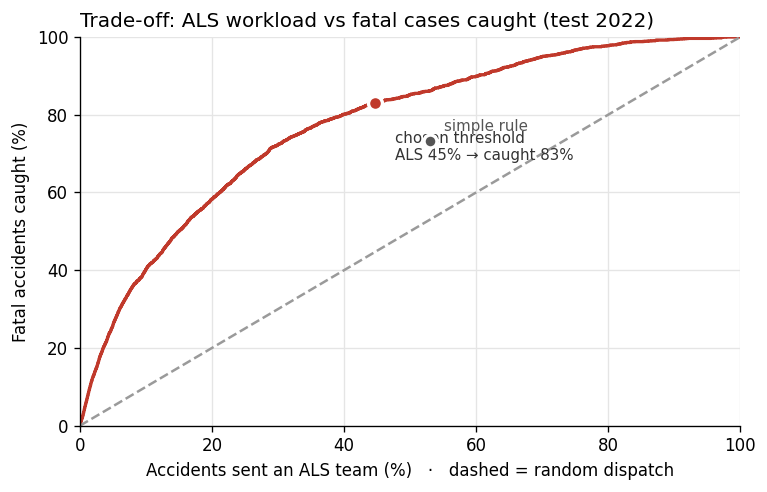

In [ ]:
chosen = results_table.loc[BEST_MODEL]
rule = results_table.loc["Baseline 2: กฎรถเสี่ยง/กลางคืน"]

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(alert_share * 100, caught_cum * 100, color=ACCENT, lw=2)
ax.plot([0, 100], [0, 100], color=MUTED, ls="--", lw=1.5)
ax.scatter([chosen["ส่ง ALS (% ของเคส)"]], [chosen["recall"] * 100], s=70, color=ACCENT,
           edgecolor="white", linewidth=2, zorder=3)
ax.annotate(f"chosen threshold\nALS {chosen['ส่ง ALS (% ของเคส)']:.0f}% → caught {chosen['recall']*100:.0f}%",
            (chosen["ส่ง ALS (% ของเคส)"], chosen["recall"] * 100), xytext=(12, -34),
            textcoords="offset points", fontsize=9, color="#333")
ax.scatter([rule["ส่ง ALS (% ของเคส)"]], [rule["recall"] * 100], s=60, color="#555",
           edgecolor="white", linewidth=2, zorder=3)
ax.annotate("simple rule", (rule["ส่ง ALS (% ของเคส)"], rule["recall"] * 100), xytext=(8, 6),
            textcoords="offset points", fontsize=9, color="#555")
ax.set_xlim(0, 100); ax.set_ylim(0, 100)
ax.set_xlabel("Accidents sent an ALS team (%)   ·   dashed = random dispatch")
ax.set_ylabel("Fatal accidents caught (%)")
ax.set_title(f"Trade-off: ALS workload vs fatal cases caught (test 2022)", loc="left", fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
tp, fn, fp = int(chosen["จับได้ (TP)"]), int(chosen["พลาด (FN)"]), int(chosen["ส่งเกิน (FP)"])
alerts = tp + fp
per100 = 100 / len(test)

print(f"โมเดล: {BEST_MODEL} · threshold {THRESHOLDS[BEST_MODEL]:.3f} · test 2022 ({len(test):,} เคส)")
print(f"• จับเคสเสียชีวิตได้ {tp:,} จาก {tp + fn:,} ราย ({chosen['recall']:.0%}) ≈ {round(chosen['recall'] * 10)} ใน 10")
print(f"• ต้องส่ง ALS {alerts:,} ครั้ง = {chosen['ส่ง ALS (% ของเคส)']:.0f}% ของเคสทั้งหมด")
print(f"• ในการส่ง ALS ทุก {round(1 / chosen['precision']) if chosen['precision'] else 0} ครั้ง มีเคสเสียชีวิตจริงประมาณ 1 ครั้ง (precision {chosen['precision']:.2f})")
print(f"• ต่อทุก 100 เคสที่รับแจ้ง: ส่ง ALS {alerts * per100:.0f} ครั้ง · จับเคสเสียชีวิตได้ {tp * per100:.1f} · พลาด {fn * per100:.1f}")
print(f"• เทียบกฎง่าย ๆ: ส่ง ALS {rule['ส่ง ALS (% ของเคส)']:.0f}% ของเคส จับได้ {rule['recall']:.0%}")

โมเดล: Random Forest · threshold 0.352 · test 2022 (21,032 เคส)
• จับเคสเสียชีวิตได้ 1,886 จาก 2,275 ราย (83%) ≈ 8 ใน 10
• ต้องส่ง ALS 9,396 ครั้ง = 45% ของเคสทั้งหมด
• ในการส่ง ALS ทุก 5 ครั้ง มีเคสเสียชีวิตจริงประมาณ 1 ครั้ง (precision 0.20)
• ต่อทุก 100 เคสที่รับแจ้ง: ส่ง ALS 45 ครั้ง · จับเคสเสียชีวิตได้ 9.0 · พลาด 1.8
• เทียบกฎง่าย ๆ: ส่ง ALS 53% ของเคส จับได้ 73%


## 6.2 ข้อเสนอแนะ

1. **ผู้ใช้ควรทำอะไร:** ศูนย์ 1669 ใช้คะแนนความเสี่ยงจากโมเดล (Random Forest) เป็นตัวช่วยเสริมตอนรับแจ้ง ถ้าคะแนนเกิน 0.352 ให้พิจารณาส่งทีม ALS → จับเคสเสียชีวิตได้ราว 8 ใน 10 (83%) โดยส่ง ALS 45% ของเคส
   - เทียบกับกฎง่าย ๆ (รถเสี่ยงหรือกลางคืน): จับเคสเสียชีวิตได้มากกว่า 219 ราย และส่ง ALS น้อยกว่า 1,761 ครั้ง (45% เทียบกับ 53% ของเคส) ในจำนวนนี้เป็นการส่งเกินจำเป็นที่ลดลง 1,980 ครั้ง
   - ถ้าตั้งให้จับได้เท่ากับกฎ (73%) โมเดลใช้ทีม ALS แค่ 30% ของเคส เทียบกับกฎที่ต้องใช้ 53%

2. **ต้นทุน:** ส่ง ALS ประมาณ 5 ครั้งต่อการจับเคสเสียชีวิตได้ 1 ราย (precision 0.20) และยังพลาดเคสเสียชีวิต 17% (389 จาก 2,275 ราย ในปี 2022)
   - ศูนย์ต้องมีทีม ALS พอรองรับช่วงที่โมเดลเตือนบ่อย คือช่วงกลางคืน (อัตราเสียชีวิต 15.9% เทียบกับกลางวัน 10.8%) และอุบัติเหตุรถจักรยานยนต์ ซึ่งโมเดลให้ส่ง ALS แทบทุกเคส

3. **ปรับได้ตามทรัพยากร:** ใช้ตารางเทียบ TARGET_RECALL ใน 6.1 เลือกจุดทำงานตามจำนวนทีม ALS ที่มี
   - ทีม ALS น้อย → ใช้ 0.80: จับได้ 78% ส่ง ALS 36%
   - ทีม ALS มาก → ใช้ 0.90: จับได้ 88% ส่ง ALS 56%
   - กลุ่มเลือก 0.85 เพราะเป็นค่าสูงสุดที่ยังส่ง ALS น้อยกว่ากฎง่าย ๆ (45% เทียบกับ 53%) ส่วนตั้งแต่ 0.90 ขึ้นไปต้องส่ง ALS เกินครึ่งของเคส

4. **เพิ่มคำถามตอนรับแจ้ง 2 ข้อ:** "รถพลิกคว่ำหรือตกถนนไหม" และ "มีคนเดินเท้าถูกชนไหม"
   - เหตุผล (จาก R5): เคสเสียชีวิตที่โมเดลพลาดส่วนใหญ่เป็นรถเก๋งหรือกระบะคันเดียวที่พลิกคว่ำ ซึ่งตอนรับแจ้งดูเสี่ยงต่ำ โดย 89% ของเคสที่พลาดเป็นรถคันเดียว (เทียบกับ 29% ในเคสที่จับได้) และ 75% เป็นรถพลิกคว่ำหรือตกถนน (เทียบกับ 18%) ส่วนเคสชนคนเดินเท้าก็พลาดบ่อย เพราะข้อมูลบอกแค่ประเภทรถ ไม่ได้บอกว่าผู้เสียชีวิตเป็นคนเดินเท้า
   - คนโทรแจ้งตอบ 2 คำถามนี้ได้ง่าย
   - *ยังพิสูจน์ไม่ได้ด้วยข้อมูลชุดนี้ เพราะลักษณะการชนในข้อมูลเป็นค่าที่เจ้าหน้าที่บันทึกภายหลัง ต้องทดลองใช้จริงก่อน*

## 6.3 ข้อจำกัดที่ข้อมูลพิสูจน์ไม่ได้

- **ครอบคลุมเฉพาะทางหลวง ทางหลวงชนบท และทางพิเศษ** ไม่รวมถนนในเมืองและถนนท้องถิ่น ใช้กับเหตุนอกโครงข่ายนี้ไม่ได้
- **ข้อมูลเป็นค่าที่เจ้าหน้าที่บันทึก ไม่ใช่สิ่งที่คนโทรแจ้งพูดจริง** ตอนใช้งานจริง ข้อมูลอาจไม่ครบหรือคลาดเคลื่อน ผลจริงจึงอาจต่ำกว่าบน test
- **เป้าหมายรวมผู้ที่เสียชีวิตทันทีที่จุดเกิดเหตุ** ซึ่งทีม ALS ช่วยไม่ได้ และข้อมูลไม่แยกว่าเสียชีวิตที่จุดเกิดเหตุหรือภายหลัง โมเดลจึงทำนาย "อุบัติเหตุรุนแรง" ไม่ใช่ "เคสที่ ALS ช่วยชีวิตได้" โดยตรง
- **ไม่มีข้อมูลเวลาที่โทรแจ้ง** (`report_datetime` เป็นเวลาบันทึกเข้าระบบ) จึงพิสูจน์ไม่ได้ว่าการส่ง ALS เร็วขึ้นช่วยลดการเสียชีวิตได้จริงเท่าไร
- **ไม่รู้จำนวนทีม ALS ที่ 1669 มีจริง** จึงบอกไม่ได้ว่าการส่ง ALS 45% ของเคสทำได้จริงหรือไม่ ต้องให้ศูนย์เลือกจุดทำงานเองจากตาราง 6.1
- **ความสัมพันธ์ไม่ใช่เหตุและผล** เช่น ฝนตกมีอัตราเสียชีวิต 7.6% ต่ำกว่าอากาศแจ่มใส 13.5% ไม่ได้แปลว่าฝนทำให้ปลอดภัยขึ้น อาจเป็นเพราะคนขับช้าลง ซึ่งข้อมูลพิสูจน์ไม่ได้
- **ช่วงโควิด 2020–2021** ปริมาณการเดินทางผิดปกติ รูปแบบใน train อาจไม่เหมือนปีปกติ
- **test มีปีเดียว (2022)** และ recall บน 2022 ต่ำกว่าเป้าที่ตั้งจาก 2021 ราว 2 จุดทุกค่า แสดงว่าข้อมูลเปลี่ยนไปตามปี ควรปรับ threshold ใหม่ทุกปี

# Part 7 · บันทึกการใช้ AI (R7)

> ต้องมีอย่างน้อย 1 ครั้งที่กลุ่ม **ไม่ทำตาม** หรือ **แก้ไข** ผลจาก AI พร้อมเหตุผล → แถว 4 และ 5

| # | คำถามที่ถาม AI | สิ่งที่ AI ให้ | สิ่งที่กลุ่มเปลี่ยน / เหตุผล |
|---|---|---|---|
| 1 | ขอไอเดียหัวข้อ SDG 2 และ SDG 11 | เสนอ 3 หัวข้อ แนะนำการทำนายความรุนแรงอุบัติเหตุสำหรับ 1669 | **ใช้ตาม** เพราะระบุผู้ใช้และการตัดสินใจได้ชัด (1669 ส่ง ALS หรือทีมพื้นฐาน) และดาวน์โหลดข้อมูลได้ทันที |
| 2 | ขอแหล่งข้อมูล | ชุดข้อมูล Kaggle 2019–2022 (81,735 แถว) พร้อมแบ่งคอลัมน์ที่ใช้ได้ / ห้ามใช้ | **ใช้ตาม** · กลุ่มโหลดเข้า Colab และตรวจเอง ได้ 81,735 แถวตรงกับที่ระบุ |
| 3 | ควรใช้ `accident_type` ไหม | แนะนำไม่ใช้ เพราะเป็นข้อมูลที่บันทึกหลังเกิดเหตุ | **ใช้ตาม** เพราะขัดกับ R1 ข้อ 2 (ต้องใช้เฉพาะข้อมูลที่รู้ตอนรับแจ้ง) · ภายหลังผล R5 พบว่าเคสที่พลาดส่วนใหญ่เป็นรถพลิกคว่ำ จึงเสนอคำถามแบบหยาบที่คนโทรตอบได้ใน R6 แทน |
| 4 | ขอโค้ดโมเดลและวิธีเลือก threshold | ตั้ง `TARGET_RECALL = 0.80` | **ไม่ใช้ค่าของ AI:** ลอง 0.80 / 0.85 / 0.90 (ตารางใน 6.1) แล้วเลือก **0.85** เพราะจับเคสเสียชีวิตได้ 1,886 ราย เพิ่มจาก 0.80 อีก 111 ราย และยังส่ง ALS 45% ของเคส น้อยกว่ากฎง่าย ๆ (53%) ส่วน 0.90 ต้องส่ง ALS 56% ซึ่งมากกว่ากฎ |
| 5 | ให้ AI ร่างข้อเสนอแนะ 6.2 | เขียนว่าโมเดล "ส่ง ALS น้อยกว่ากฎ 1,980 ครั้ง" | **แก้ผลจาก AI:** ตรวจกับตาราง 4.3 แล้วพบว่า 1,980 คือส่วนต่างของการส่งเกินจำเป็น (FP) เท่านั้น ไม่ใช่การส่ง ALS ทั้งหมด ตัวเลขที่ถูกคือ 1,761 ครั้ง (กฎส่ง 11,157 − โมเดลส่ง 9,396) |

# สรุปตัวเลขสำหรับโปสเตอร์
ทุกตัวเลขบนโปสเตอร์ควรมาจากเซลล์นี้ · ก่อนส่งให้กด **Runtime → Restart session and run all** แล้วเช็กอีกครั้ง

In [ ]:
summary = {
    "R2 จำนวนแถวทั้งหมด": f"{len(df):,}",
    "R2 train 2019–2021 (แถว)": f"{len(train):,}",
    "R2 test 2022 (แถว)": f"{len(test):,}",
    "R2 สัดส่วนเคสเสียชีวิตทั้งหมด": f"{df[TARGET].mean():.1%}",
    "R3 อัตราเสียชีวิตเฉลี่ยใน train": f"{BASE_RATE:.1f}%",
    "R4 โมเดลที่เลือก": BEST_MODEL,
    "R4 threshold": f"{THRESHOLDS[BEST_MODEL]:.3f}",
}
for name, row in results_table.iterrows():
    summary[f"R4 {name}"] = (f"recall {row['recall']:.2f} · precision {row['precision']:.2f} · "
                             f"accuracy {row['accuracy']:.2f} · ส่ง ALS {row['ส่ง ALS (% ของเคส)']:.0f}%")
summary["R5 อัตราพลาดเคสเสียชีวิต (FN)"] = f"{OVERALL_MISS:.0f}%"
summary["R5 feature สำคัญที่สุด 3 อันดับ"] = ", ".join(importance.sort_values(ascending=False).index[:3])
summary["R6 ส่ง ALS ต่อเคสเสียชีวิตที่จับได้ 1 ราย"] = f"{(tp + fp) / tp:.1f} ครั้ง" if tp else "-"

pd.Series(summary, name="ค่า").to_frame()

,ค่า
R2 จำนวนแถวทั้งหมด,"81,735"
R2 train 2019–2021 (แถว),"60,703"
R2 test 2022 (แถว),"21,032"
R2 สัดส่วนเคสเสียชีวิตทั้งหมด,12.4%
R3 อัตราเสียชีวิตเฉลี่ยใน train,12.9%
R4 โมเดลที่เลือก,Random Forest
R4 threshold,0.352
R4 Baseline 1: ไม่เสียชีวิตทุกเคส,recall 0.00 · precision 0.00 · accuracy 0.89 ·...
R4 Baseline 2: กฎรถเสี่ยง/กลางคืน,recall 0.73 · precision 0.15 · accuracy 0.52 ·...
R4 Logistic Regression,recall 0.84 · precision 0.17 · accuracy 0.53 ·...


# ภาคผนวก · กราฟและตัวเลขสำหรับโปสเตอร์

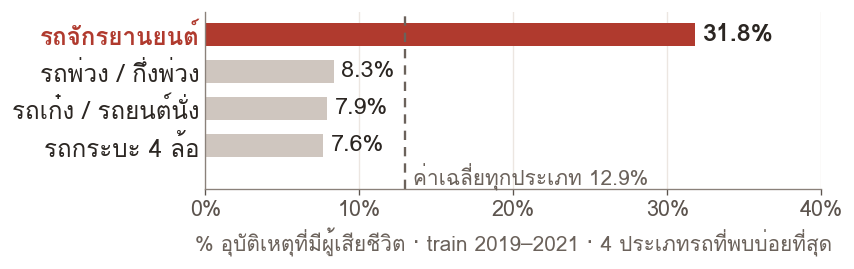

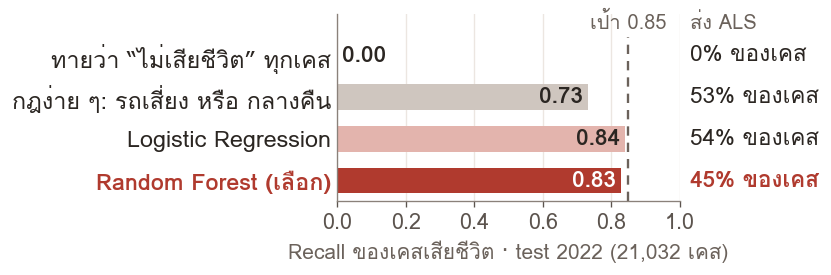

บันทึกไฟล์ poster_R3.svg/png และ poster_R4.svg/png แล้ว (ดูได้ในแถบ Files ทางซ้าย)


In [ ]:
# ===== กราฟสำหรับโปสเตอร์ (R3, R4) — สร้างจาก vt และ results_table ด้านบน =====
!apt-get -qq install -y fonts-thai-tlwg > /dev/null
import glob
import matplotlib.transforms as mtrans
from matplotlib import font_manager as fm
for f in glob.glob("/usr/share/fonts/**/Loma*.*tf", recursive=True):
    fm.fontManager.addfont(f)

TH_VEHICLE = {"motorcycle": "รถจักรยานยนต์", "large truck with trailer": "รถพ่วง / กึ่งพ่วง",
              "private/passenger car": "รถเก๋ง / รถยนต์นั่ง", "4-wheel pickup truck": "รถกระบะ 4 ล้อ"}
TH_MODEL = {"Baseline 1: ไม่เสียชีวิตทุกเคส": "ทายว่า “ไม่เสียชีวิต” ทุกเคส",
            "Baseline 2: กฎรถเสี่ยง/กลางคืน": "กฎง่าย ๆ: รถเสี่ยง หรือ กลางคืน"}
P_INK, P_MUTED, P_ACC, P_GRAY, P_GRID = "#2b2622", "#6b625b", "#b03a2e", "#cfc6bf", "#ece6e1"
MM = 1 / 25.4
POSTER_STYLE = {"font.family": "Loma", "svg.fonttype": "path", "axes.grid": False,
                "axes.spines.top": False, "axes.spines.right": False,
                "axes.edgecolor": "#8a817a", "axes.linewidth": 0.8,
                "xtick.color": "#5c544e", "ytick.color": P_INK, "xtick.labelsize": 13}

with plt.rc_context(POSTER_STYLE):
    # ---------- R3: อัตราเสียชีวิต 4 ประเภทรถที่พบบ่อยที่สุด (train) ----------
    top4 = vt.sort_values("n", ascending=False).head(4).sort_values("rate_%")
    labels = [TH_VEHICLE.get(i, i) for i in top4.index]
    is_moto = [i == "motorcycle" for i in top4.index]
    fig, ax = plt.subplots(figsize=(178 * MM, 54 * MM))
    y = list(range(len(top4)))
    ax.barh(y, top4["rate_%"], color=[P_ACC if m else P_GRAY for m in is_moto], height=0.62)
    ax.axvline(BASE_RATE, color=P_MUTED, ls=(0, (4, 3)), lw=1.4)
    ax.text(BASE_RATE + 0.5, -0.85, f"ค่าเฉลี่ยทุกประเภท {BASE_RATE:.1f}%", color=P_MUTED, fontsize=12.5, va="center")
    for i, (v, m) in enumerate(zip(top4["rate_%"], is_moto)):
        ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=15 if m else 14, color=P_INK, fontweight="bold" if m else "normal")
    ax.set_yticks(y, labels)
    for t, m in zip(ax.get_yticklabels(), is_moto):
        t.set_fontsize(14.5)
        if m:
            t.set_fontweight("bold"); t.set_color(P_ACC)
    ax.set_xlim(0, 40); ax.set_ylim(-1.15, len(top4) - 0.4)
    ax.set_xticks([0, 10, 20, 30, 40], ["0%", "10%", "20%", "30%", "40%"])
    ax.grid(axis="x", color=P_GRID, lw=0.8); ax.set_axisbelow(True)
    ax.tick_params(axis="y", length=0)
    ax.set_xlabel("% อุบัติเหตุที่มีผู้เสียชีวิต · train 2019–2021 · 4 ประเภทรถที่พบบ่อยที่สุด", fontsize=12.5, color=P_MUTED)
    fig.tight_layout(pad=0.3)
    fig.savefig("poster_R3.svg", transparent=True)
    fig.savefig("poster_R3.png", dpi=300)
    plt.show()

    # ---------- R4: recall บน test 2022 ----------
    rows = results_table.iloc[::-1]
    names = list(rows.index)
    fig, ax = plt.subplots(figsize=(178 * MM, 55 * MM))
    cols = [P_ACC if n == BEST_MODEL else ("#e3b4ad" if n in MODELS else P_GRAY) for n in names]
    ax.barh(range(len(rows)), rows["recall"], color=cols, height=0.62)
    top = len(rows) - 0.55
    ax.vlines(TARGET_RECALL, -0.5, top, color=P_MUTED, ls=(0, (4, 3)), lw=1.4)
    ax.text(TARGET_RECALL, top + 0.1, f"เป้า {TARGET_RECALL:.2f}", color=P_MUTED, fontsize=12, ha="center", va="bottom")
    right = mtrans.blended_transform_factory(ax.transAxes, ax.transData)
    ax.text(1.03, top + 0.1, "ส่ง ALS", transform=right, fontsize=12, color=P_MUTED, va="bottom")
    for i, (n, r, a) in enumerate(zip(names, rows["recall"], rows["ส่ง ALS (% ของเคส)"])):
        best = n == BEST_MODEL
        if r > 0.2:
            ax.text(r - 0.015, i, f"{r:.2f}", va="center", ha="right", fontsize=13.5,
                    color="#fff" if best else P_INK, fontweight="bold")
        else:
            ax.text(r + 0.015, i, f"{r:.2f}", va="center", fontsize=13.5, color=P_INK, fontweight="bold")
        ax.text(1.03, i, f"{a:.0f}% ของเคส", transform=right, va="center", fontsize=13.5,
                color=P_ACC if best else P_INK, fontweight="bold" if best else "normal")
    ax.set_yticks(range(len(rows)), [TH_MODEL.get(n, n) + (" (เลือก)" if n == BEST_MODEL else "") for n in names])
    for t, n in zip(ax.get_yticklabels(), names):
        t.set_fontsize(14)
        if n == BEST_MODEL:
            t.set_fontweight("bold"); t.set_color(P_ACC)
    ax.set_xlim(0, 1.0); ax.set_ylim(-0.5, len(rows))
    ax.set_xticks([0, .2, .4, .6, .8, 1.0])
    ax.grid(axis="x", color=P_GRID, lw=0.8); ax.set_axisbelow(True)
    ax.tick_params(axis="y", length=0)
    ax.set_xlabel(f"Recall ของเคสเสียชีวิต · test 2022 ({len(test):,} เคส)", fontsize=12.5, color=P_MUTED)
    fig.tight_layout(pad=0.3)
    fig.subplots_adjust(right=0.80)
    fig.savefig("poster_R4.svg", transparent=True)
    fig.savefig("poster_R4.png", dpi=300)
    plt.show()

print("บันทึกไฟล์ poster_R3.svg/png และ poster_R4.svg/png แล้ว (ดูได้ในแถบ Files ทางซ้าย)")

In [ ]:
# ===== ตัวเลขบนโปสเตอร์ที่คำนวณต่อจากผลด้านบน =====
moto_rate = vt.loc["motorcycle", "rate_%"]
car_rate = vt.loc["private/passenger car", "rate_%"]
fn_cases = fatal_cases[fatal_cases["outcome"] == "FN พลาด"]
tp_cases = fatal_cases[fatal_cases["outcome"] == "TP จับได้"]
single = fatal_cases["number_of_vehicles_involved"] == 1
rollover = fatal_cases["accident_type"].str.startswith("rollover")
rule = results_table.loc["Baseline 2: กฎรถเสี่ยง/กลางคืน"]
best = results_table.loc[BEST_MODEL]
c = compare_targets
moto_caught = mr_vt.loc["motorcycle"]

poster_numbers = {
    "R3 รถจักรยานยนต์ เทียบค่าเฉลี่ย": f"{moto_rate / BASE_RATE:.1f} เท่า",
    "R3 รถจักรยานยนต์ เทียบรถเก๋ง": f"{moto_rate / car_rate:.1f} เท่า",
    "R4 ถ้า recall เท่ากฎ (TARGET 0.75) ส่ง ALS": f"{c.loc['TARGET_RECALL 0.75', 'ส่ง ALS (% ของเคส)']:.0f}%",
    "R5 เคสที่พลาดเป็นรถเก๋ง/กระบะ 4 ล้อ": f"{fn_cases['vehicle_type'].isin(['private/passenger car', '4-wheel pickup truck']).mean():.0%}",
    "R5 รถคันเดียว (พลาด / จับได้)": f"{single[fn_cases.index].mean():.0%} / {single[tp_cases.index].mean():.0%}",
    "R5 รถพลิกคว่ำ/ตกถนน (พลาด / จับได้)": f"{rollover[fn_cases.index].mean():.0%} / {rollover[tp_cases.index].mean():.0%}",
    "R5 รถจักรยานยนต์ที่จับได้": f"{int(moto_caught['caught']):,} จาก {int(moto_caught['n']):,}",
    "R6 ส่ง ALS ต่อการจับได้ 1 ราย": f"{(best['จับได้ (TP)'] + best['ส่งเกิน (FP)']) / best['จับได้ (TP)']:.1f} ครั้ง",
    "R6 จับได้มากกว่ากฎ": f"{best['จับได้ (TP)'] - rule['จับได้ (TP)']:,.0f} ราย",
    "R6 ส่ง ALS (ทั้งหมด) น้อยกว่ากฎ": f"{(rule['จับได้ (TP)'] + rule['ส่งเกิน (FP)']) - (best['จับได้ (TP)'] + best['ส่งเกิน (FP)']):,.0f} ครั้ง",
    "R6 ส่งเกินจำเป็นน้อยกว่ากฎ": f"{rule['ส่งเกิน (FP)'] - best['ส่งเกิน (FP)']:,.0f} ครั้ง",
    "R7 0.85 จับได้เพิ่มจาก 0.80": f"{c.loc['TARGET_RECALL 0.85', 'จับได้ (TP)'] - c.loc['TARGET_RECALL 0.80', 'จับได้ (TP)']:,.0f} ราย",
    "R7 0.90 ส่ง ALS": f"{c.loc['TARGET_RECALL 0.90', 'ส่ง ALS (% ของเคส)']:.0f}%",
}
pd.Series(poster_numbers, name="ค่า").to_frame()

,ค่า
R3 รถจักรยานยนต์ เทียบค่าเฉลี่ย,2.5 เท่า
R3 รถจักรยานยนต์ เทียบรถเก๋ง,4.0 เท่า
R4 ถ้า recall เท่ากฎ (TARGET 0.75) ส่ง ALS,30%
R5 เคสที่พลาดเป็นรถเก๋ง/กระบะ 4 ล้อ,82%
R5 รถคันเดียว (พลาด / จับได้),89% / 29%
R5 รถพลิกคว่ำ/ตกถนน (พลาด / จับได้),75% / 18%
R5 รถจักรยานยนต์ที่จับได้,969 จาก 969
R6 ส่ง ALS ต่อการจับได้ 1 ราย,5.0 ครั้ง
R6 จับได้มากกว่ากฎ,219 ราย
R6 ส่ง ALS (ทั้งหมด) น้อยกว่ากฎ,"1,761 ครั้ง"
